<a href="https://colab.research.google.com/github/2311090021-prog/deep_learning_huph/blob/main/NNLAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Train: (60000, 28, 28)
Test: (10000, 28, 28)
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9023 - loss: 0.3500 - val_accuracy: 0.9597 - val_loss: 0.1398
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9594 - loss: 0.1393 - val_accuracy: 0.9703 - val_loss: 0.1032
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9714 - loss: 0.0966 - val_accuracy: 0.9737 - val_loss: 0.0902
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9784 - loss: 0.0726 - val_accuracy: 0.9738 - val_loss: 0.0856
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9821 - loss: 0.0580 - val_accuracy: 0.9772 - val_loss: 0.0776
Test loss: 0.0771
Test accuracy: 97.63%


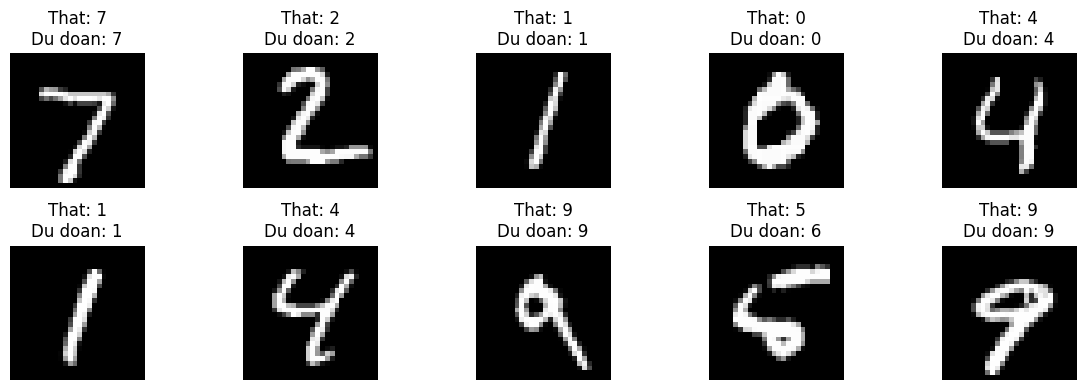

In [10]:

# ============================================================
# BAI 1: NHAN DIEN CHU CAI BANG MANG NORON ANN
# Dataset: EMNIST Letters
# ============================================================

!pip -q install emnist

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from emnist import extract_training_samples, extract_test_samples
from sklearn.metrics import classification_report, confusion_matrix

# 1. THIET LAP
tf.keras.utils.set_random_seed(42)

print("=" * 60)
print("BAI 1: NHAN DIEN CHU CAI BANG MANG NORON")
print("=" * 60)

# 2. TAI DU LIEU
print("\nDang tai du lieu EMNIST Letters...")

X_train, y_train = extract_training_samples("letters")
X_test, y_test = extract_test_samples("letters")

print("Kich thuoc X_train:", X_train.shape)
print("Kich thuoc y_train:", y_train.shape)
print("Kich thuoc X_test:", X_test.shape)
print("Kich thuoc y_test:", y_test.shape)

# 3. TIEN XU LY DU LIEU
# Chuan hoa pixel tu [0, 255] ve [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# EMNIST Letters co nhan tu 1 den 26
# Chuyen ve 0 den 25 de phu hop voi mang ANN
y_train = y_train.astype("int32") - 1
y_test = y_test.astype("int32") - 1

# 4. HIEN THI DU LIEU MAU
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title("Chu cai: " + chr(y_train[i] + 65))
    plt.axis("off")

plt.suptitle("10 anh chu cai dau tien")
plt.tight_layout()
plt.show()

# 5. XAY DUNG MANG NORON ANN
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(26, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nCAU TRUC MO HINH:")
model.summary()

# 6. HUAN LUYEN MO HINH
print("\nBAT DAU HUAN LUYEN...")

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# 7. DANH GIA MO HINH
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("\n" + "=" * 60)
print("KET QUA DANH GIA BAI 1")
print("=" * 60)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Do chinh xac  : {test_accuracy * 100:.2f}%")

# 8. VE BIEU DO ACCURACY VA LOSS
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy qua cac Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss qua cac Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 9. DU DOAN 10 ANH TRONG TAP TEST
probabilities = model.predict(X_test[:10], verbose=0)
predictions = np.argmax(probabilities, axis=1)

print("\nKET QUA NHAN DIEN 10 ANH:")
plt.figure(figsize=(12, 5))

for i in range(10):
    actual = chr(y_test[i] + 65)
    predicted = chr(predictions[i] + 65)

    print(
        f Anh {i+1}: Chu that = {actual}, "
        f"Du doan = {predicted}"
    )

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    plt.title(
        f"That: {actual}\nDu doan: {predicted}",
        color="green" if actual == predicted else "red"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

# 10. BAO CAO PHAN LOAI
y_pred_all = np.argmax(
    model.predict(X_test, batch_size=256, verbose=0),
    axis=1
)

print("\nBAO CAO PHAN LOAI:")
print(classification_report(
    y_test,
    y_pred_all,
    labels=np.arange(26),
    target_names=list("ABCDEFGHIJKLMNOPQRSTUVWXYZ"),
    zero_division=0
))

# 11. MA TRAN NHAM LAN
cm = confusion_matrix(y_test, y_pred_all)

plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix - EMNIST Letters")
plt.xlabel("Nhan du doan")
plt.ylabel("Nhan thuc te")
plt.xticks(range(26), list("ABCDEFGHIJKLMNOPQRSTUVWXYZ"),
           rotation=90)
plt.yticks(range(26), list("ABCDEFGHIJKLMNOPQRSTUVWXYZ"))
plt.colorbar()
plt.tight_layout()
plt.show()

# 12. LUU MO HINH
model.save("/content/ann_letter_model.keras")
print("\nDa luu mo hinh: /content/ann_letter_model.keras")

# 13. NHAN XET TU DONG
print("\nNHAN XET:")
print(f"- Do chinh xac tren tap test: {test_accuracy*100:.2f}%.")

if test_accuracy >= 0.85:
    print("- Mo hinh dat do chinh xac kha tot tren tap kiem tra.")
else:
    print("- Mo hinh con nham lan; co the thu tang epoch hoac dieu chinh kien truc.")

if history.history["val_loss"][-1] > history.history["loss"][-1] * 1.2:
    print("- Validation loss cao hon train loss dang ke; can kiem tra overfitting.")

print("- ANN su dung cac dac trung pixel de phan loai 26 chu cai.")
print("- Ket qua co the cai thien bang CNN, tien xu ly anh va dieu chinh sieu tham so.")



# # Nhận xét
Mô hình mạng nơ-ron ANN được xây dựng với hai lớp ẩn gồm 128 và 64 nơ-ron, sử dụng hàm kích hoạt ReLU và lớp đầu ra Softmax gồm 10 nơ-ron tương ứng với các chữ số từ 0 đến 9. Mô hình được huấn luyện trong 5 epoch trên bộ dữ liệu MNIST.
- Kết quả huấn luyện: Mô hình học được đặc trưng của các chữ số viết tay thông qua dữ liệu hình ảnh đã chuẩn hóa.
- Đánh giá mô hình: Test Accuracy cho biết tỷ lệ dự đoán đúng trên tập kiểm tra. Có thể quan sát thêm biểu đồ dự đoán để xác định những chữ số được nhận diện chính xác hoặc bị nhầm lẫn.
- Hạn chế: Các chữ số có hình dạng gần giống nhau có thể bị nhận diện sai. Mô hình ANN cũng chưa khai thác tốt đặc trưng không gian của hình ảnh như mạng CNN.
- Kết luận: Code đã triển khai đầy đủ quy trình xây dựng, huấn luyện và đánh giá mạng nơ-ron cơ bản. Hiệu quả thực tế cần căn cứ vào Test Accuracy và kết quả dự đoán hiển thị sau khi chạy chương trình.

5 dong dau:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Kich thuoc: (768, 9)

Thong ke:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3422 - loss: 0.8043 - val_accuracy: 0.3496 - val_loss: 0.7221
Epoch 2/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3564 - loss: 0.7388 - val_accuracy: 0.4228 - val_loss: 0.6855
Epoch 3/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4542 - loss: 0.7087 - val_accuracy: 0.6179 - val_loss: 0.6666
Epoch 4/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5642 - loss: 0.6918 - val_accuracy: 0.7236 - val_loss: 0.6537
Epoch 5/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6802 - loss: 0.6710 - val_accuracy: 0.7642 - val_loss: 0.6405
Epoch 6/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7026 - loss: 0.6562 - val_accuracy: 0.8049 - val_loss: 0.6253
Epoch 7/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7373 - loss: 0.6378 - val_accuracy: 0.8211 - val_loss: 0.6040
Epoch 8/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7475 - loss: 0.6168 - val_accuracy: 0.8130 - val_loss

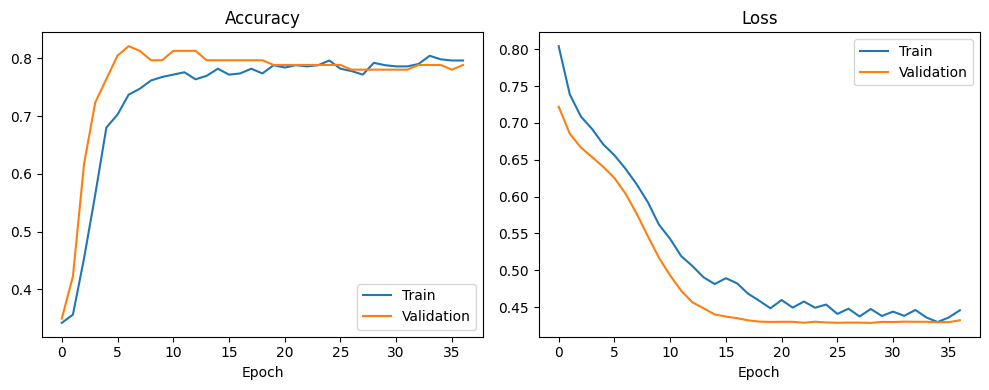

In [11]:

import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

# 1. Doc dataset co san
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies", "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI",
    "DiabetesPedigreeFunction", "Age", "Outcome"
]

df = pd.read_csv(url, names=columns)

print("5 dong dau:")
display(df.head())

print("\nKich thuoc:", df.shape)
print("\nThong ke:")
display(df.describe())

# 2. Tach X va y
X = df.drop(columns="Outcome").copy()
y = df["Outcome"]

# 3. Chia train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Xu ly cac gia tri 0 co the la du lieu thieu
missing_cols = [
    "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI"
]

for col in missing_cols:
    X_train[col] = X_train[col].replace(0, np.nan)
    X_test[col] = X_test[col].replace(0, np.nan)

medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

# 5. Chuan hoa
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 6. Xay dung ANN
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(8,)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 7. Huan luyen
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True
        )
    ],
    verbose=1
)

# 8. Du doan va danh gia
prob = model.predict(X_test, verbose=0).ravel()
y_pred = (prob >= 0.5).astype(int)

print("\nKET QUA MO HINH")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred, zero_division=0):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# 9. Bieu do huan luyen
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()


# #Nhận xét
Mô hình ANN sử dụng 8 biến đầu vào, gồm số lần mang thai, glucose, huyết áp, độ dày da, insulin, BMI, chỉ số tiền sử tiểu đường gia đình và tuổi. Mạng gồm hai lớp ẩn với 16 và 8 nơ-ron, sử dụng ReLU, Dropout và lớp đầu ra Sigmoid để phân loại hai nhóm.
- Tiền xử lý dữ liệu: Dữ liệu được chia thành tập huấn luyện và tập kiểm tra theo tỷ lệ 80:20. Các giá trị 0 không hợp lý ở một số chỉ số được thay bằng giá trị thiếu, sau đó điền bằng trung vị của tập huấn luyện. Các biến đầu vào được chuẩn hóa bằng StandardScaler.
- Đánh giá mô hình: Accuracy phản ánh độ chính xác tổng thể; Precision thể hiện tỷ lệ dự đoán dương tính đúng; Recall đánh giá khả năng phát hiện các trường hợp có nhãn mắc bệnh; F1-score cân bằng Precision và Recall.
- Ma trận nhầm lẫn: Giúp xác định số trường hợp dự đoán đúng, số trường hợp mắc bệnh bị bỏ sót và số trường hợp không mắc bệnh nhưng bị dự đoán nhầm.
- Hạn chế: Bộ dữ liệu có quy mô tương đối nhỏ và chỉ đại diện cho một nhóm dân số nhất định. Kết quả còn phụ thuộc vào cách tiền xử lý, cấu trúc mô hình và ngưỡng phân loại 0,5.